In [1]:
 # import

import torch
import torch.nn as nn
import torchvision
import matplotlib.pyplot as plt
from torchvision import transforms
from torch.utils.data import DataLoader


In [2]:
data_transform = transforms.Compose([
    transforms.ToTensor()
])

In [3]:
# import dataset

train_dataset = torchvision.datasets.MNIST(root = "./data", train = True, download = True, transform = data_transform)
val_dataset = torchvision.datasets.MNIST(root = "./data", train = False, download = True, transform = data_transform)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 521kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.51MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.0MB/s]


In [4]:
# define variable

num_classes = 10
batch_size = 64
num_channels = 1
img_size = 28
patch_size = 7
num_patches = (img_size // patch_size)**2
embedding_dim = 64
attention_heads = 4
transformer_blocks = 4
mlp_hidden_nodes = 128
learning_rate = 1e-3
epochs = 5



In [5]:
# dataset batch

train_loader = DataLoader(dataset = train_dataset, batch_size = 64, shuffle = True)
val_loader = DataLoader(dataset = val_dataset, batch_size = 64, shuffle = True)

In [6]:
# part 1: patch embedding
# part 2: transformer encoder
# part 3: MLP head
# part 4: transformer class

In [7]:
# part 1
class PatchEmbedding(nn.Module):
  def __init__(self):
    super().__init__()

    self.patch_embedding = nn.Conv2d(num_channels, embedding_dim, kernel_size = patch_size, stride = patch_size)

  def forward(self, x):
        x = self.patch_embedding(x)       # ( output is 64, 64, 4,4 )
        x = x.flatten(2)                  # flatten 4x4 into 16 . (2 refers to 4,4) -> dimension 64,64,16
        x = x.transpose(1,2)              # dimension 64,16,64
        return x

In [13]:
# part 2

class TransformerEncoder(nn.Module):
  def __init__(self):
    super().__init__()

    self.layer_norm1 = nn.LayerNorm(embedding_dim)
    self.layer_norm2 = nn.LayerNorm(embedding_dim)
    self.multihead_attention = nn.MultiheadAttention(embedding_dim, attention_heads, batch_first = True)
    self.mlp = nn.Sequential(
        nn.Linear(embedding_dim, mlp_hidden_nodes),
        nn.GELU(),
        nn.Linear(mlp_hidden_nodes, embedding_dim)
    )

  def forward(self, x):
    residual = x
    x = self.layer_norm1(x)
    x = self.multihead_attention(x,x,x)[0]
    x = x + residual
    residual = x
    x = self.layer_norm2(x)
    x = self.mlp(x)
    x = x+ residual

    return x

In [14]:
# part 3

class MLPHead(nn.Module):
  def __init__(self):
    super().__init__()

    self.layer_norm1 = nn.LayerNorm(embedding_dim)
    self.mlp  = nn.Linear(embedding_dim, num_classes)

  def forward(self, x):
    x = self.layer_norm1(x)
    x = self.mlp(x)
    return x     # 10 dimentions


In [15]:
class VisionTransformer(nn.Module):

  def __init__(self):
    super().__init__()

    self.patch_embedding = PatchEmbedding()
    # cls token
    self.cls_token = nn.Parameter(torch.randn(1,1, embedding_dim))
    # position embedding
    self.position_embedding = nn.Parameter(torch.randn(1, num_patches+1, embedding_dim))

    self.transformer_blocks = nn.Sequential(
        *[TransformerEncoder() for _ in range(transformer_blocks)]
    )

    self.mlp_head = MLPHead()

  def forward(self, x):
    x = self.patch_embedding(x)
    class_token = self.cls_token.expand(x.size(0), -1, -1)
    x = torch.cat((class_token, x), dim =1)
    x = x + self.position_embedding
    x = self.transformer_blocks(x)

    x = x[:,0]
    x = self.mlp_head(x)

    return x
    # cls token passed into MLP head

In [16]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = VisionTransformer().to(device)

optimizer = torch.optim.Adam(model.parameters(), lr = learning_rate)

criterion = nn.CrossEntropyLoss()

In [17]:
# training

for epoch in range(epochs):
  model.train()
  total_loss = 0
  correct_epochs = 0
  total_epoch = 0

  print(f"\n Epoch: {epoch+1}")

  for batch_idx, (images, labels) in enumerate(train_loader):
    images , labels = images.to(device), labels.to(device)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

    total_loss += loss.item()
    preds = outputs.argmax(dim =1 )
    correct = (preds == labels).sum().item()
    accuracy = 100.0*(correct/labels.size(0))

    correct_epochs += correct
    total_epoch += labels.size(0)

    if batch_idx%100 == 0:
      print(f" Batch {batch_idx+1:3d}: Loss: {loss.item():4f}, Accuracy: {accuracy:.2f}%")







 Epoch: 1
 Batch   1: Loss: 2.503169, Accuracy: 4.69%
 Batch 101: Loss: 0.568876, Accuracy: 79.69%
 Batch 201: Loss: 0.495328, Accuracy: 84.38%
 Batch 301: Loss: 0.317757, Accuracy: 90.62%
 Batch 401: Loss: 0.160243, Accuracy: 93.75%
 Batch 501: Loss: 0.202317, Accuracy: 90.62%
 Batch 601: Loss: 0.318324, Accuracy: 93.75%
 Batch 701: Loss: 0.125797, Accuracy: 95.31%
 Batch 801: Loss: 0.148551, Accuracy: 96.88%
 Batch 901: Loss: 0.080181, Accuracy: 96.88%

 Epoch: 2
 Batch   1: Loss: 0.050559, Accuracy: 98.44%
 Batch 101: Loss: 0.065814, Accuracy: 96.88%
 Batch 201: Loss: 0.121893, Accuracy: 95.31%
 Batch 301: Loss: 0.128250, Accuracy: 95.31%
 Batch 401: Loss: 0.113686, Accuracy: 96.88%
 Batch 501: Loss: 0.074313, Accuracy: 96.88%
 Batch 601: Loss: 0.184067, Accuracy: 95.31%
 Batch 701: Loss: 0.046808, Accuracy: 98.44%
 Batch 801: Loss: 0.102090, Accuracy: 96.88%
 Batch 901: Loss: 0.186348, Accuracy: 92.19%

 Epoch: 3
 Batch   1: Loss: 0.047639, Accuracy: 98.44%
 Batch 101: Loss: 0.022

In [18]:

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        preds = torch.argmax(outputs, dim=1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

test_acc = 100.0 * correct / total

print(f"\n==> Val Accuracy: {test_acc:.2f}%")


==> Val Accuracy: 97.62%


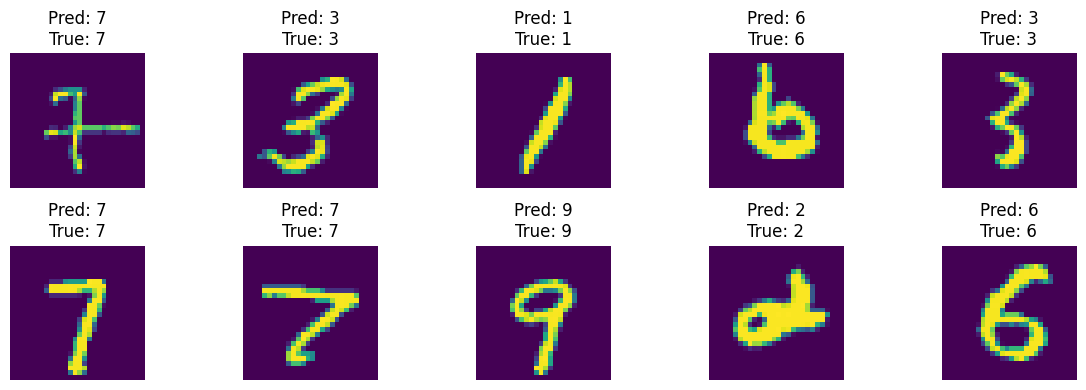

In [23]:
import matplotlib.pyplot as plt

# Define class names for MNIST dataset
class_names = [str(i) for i in range(10)]

# Show 10 predictions from the first validation batch
model.eval()

images, labels = next(iter(val_loader))
images, labels = images.to(device), labels.to(device)

with torch.no_grad():
    outputs = model(images)
    preds = outputs.argmax(dim=1)

# Move to CPU for plotting
images = images.cpu()
preds = preds.cpu()
labels = labels.cpu()

# Plot first 10 images
plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Convert image from CHW -> HWC
    img = images[i].permute(1, 2, 0)

    # If image was normalized, optionally unnormalize here
    img = img.clamp(0, 1)

    plt.imshow(img)

    plt.title(
        f"Pred: {class_names[preds[i]]}\n"
        f"True: {class_names[labels[i]]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()